# Background correlation and local attribution

I use MNIST digits 1 and 2 with horizontal and vertical stripe backgrounds to see whether small background edits can predict the effect of changing the entire background. The default experiment uses 80 test images, two training seeds and four levels of digit-background correlation.

In [1]:
import os
from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from IPython.display import display

FULL_RUN = False
SEEDS = [11, 23, 41, 53, 67] if FULL_RUN else [11, 23]
N_TEST_PER_DIGIT = 200 if FULL_RUN else 40
AGREEMENTS = (.50, .75, .95, 1.00)
SIZES = (3, 5, 9)
STRIDE = 3
EPOCHS = 4
OUT = Path("mnist_patch_results")
OUT.mkdir(exist_ok=True)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

GPU available: False


## Dataset

The test images stay fixed across models. During training, the stripe orientation agrees with the digit label 50%, 75%, 95% or 100% of the time. Both stripe patterns have the same intensity distribution.

In [2]:
(raw_train, train_y), (raw_test, test_y) = keras.datasets.mnist.load_data()

def balanced_ids(labels, per_digit, seed):
    rng = np.random.default_rng(seed)
    groups = [rng.choice(np.flatnonzero(labels == d), per_digit, replace=False)
              for d in (1, 2)]
    return rng.permutation(np.concatenate(groups))

train_ids = balanced_ids(train_y, 4000, 73)
test_ids = balanced_ids(test_y, N_TEST_PER_DIGIT, 81)
train_ink = raw_train[train_ids].astype("float32") / 255
ink = raw_test[test_ids].astype("float32") / 255
y = train_y[train_ids].astype(int) - 1
digit = test_y[test_ids]
r, col = np.indices((28, 28))
H, V = (0.25 * ((np.stack([r, col]) // 3) % 2)).astype("float32")

def render(d, b):
    return d + (1 - d) * b

horizontal, vertical = render(ink, H), render(ink, V)
assert np.array_equal(np.sort(H.ravel()), np.sort(V.ravel()))
assert np.allclose(horizontal - vertical, (1 - ink) * (H - V), atol=1e-6)
print("Train:", len(y), "| held out:", len(digit))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: 8000 | held out: 80


## CNN and prediction margin

The margin is the logit for digit 2 minus the logit for digit 1. A positive margin predicts 2; otherwise the prediction is 1. I use the absolute change in margin after swapping the background as the measure of background sensitivity. The negative absolute initial margin serves as a baseline for predicting flips.

In [3]:
def train_model(seed, agreement):
    keras.utils.set_random_seed(seed)
    rng = np.random.default_rng(seed)
    aligned = np.zeros(len(y), dtype=bool)
    for label in (0, 1):
        ids = rng.permutation(np.flatnonzero(y == label))
        aligned[ids[:round(agreement * len(ids))]] = True
    use_v = np.where(aligned, y == 1, y == 0)
    images = render(train_ink, np.where(use_v[:, None, None], V, H))
    model = keras.Sequential([
        keras.Input((28, 28, 1)), keras.layers.Conv2D(12, 3, activation="relu"),
        keras.layers.MaxPooling2D(), keras.layers.Conv2D(24, 3, activation="relu"),
        keras.layers.MaxPooling2D(), keras.layers.Flatten(),
        keras.layers.Dense(32, activation="relu"), keras.layers.Dense(2)
    ])
    model.compile(optimizer="adam",
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    model.fit(images[..., None], y, epochs=EPOCHS, batch_size=128,
              shuffle=False, verbose=0)
    return model

def make_margin(model):
    @tf.function(input_signature=[tf.TensorSpec([None, 28, 28], tf.float32)])
    def score(batch):
        logits = model(batch[..., None], training=False)
        return logits[:, 1] - logits[:, 0]
    return lambda images: score(images).numpy()

## Patch attribution

I scan 3×3, 5×5 and 9×9 patches with a stride of 3, using only patches that do not overlap the digit. Each patch is replaced with gray (0.125) or the corresponding vertical stripe pattern. The local score is the largest absolute change in margin. Heatmaps average signed changes at overlapping locations; gray marks pixels that were not tested.

In [4]:
def placements(d, k):
    starts = np.unique(np.r_[np.arange(0, 29-k, STRIDE), 28-k])
    return [(r, c) for r in starts for c in starts if not d[r:r+k, c:c+k].any()]

locations = {(i, k): placements(d, k) for i, d in enumerate(ink) for k in SIZES}
def local_scores(score, mh, k, mode, ids, want_maps=False):
    maxima = np.full(len(ids), np.nan)
    maps = {}
    for start in range(0, len(ids), 12):
        group = ids[start:start+12]
        edits, spans = [], []
        for i in group:
            sites = locations[i, k]
            batch = np.repeat(horizontal[i:i+1], len(sites), axis=0)
            for image, (r, c) in zip(batch, sites):
                image[r:r+k, c:c+k] = (0.125 if mode == "gray" else V[r:r+k, c:c+k])
            edits.append(batch)
            spans.append(len(batch))
        if not sum(spans):
            continue
        batch = np.concatenate(edits)
        changed = np.concatenate([score(batch[j:j+256]) for j in range(0, len(batch), 256)])
        offset = 0
        for j, (i, count) in enumerate(zip(group, spans)):
            delta = changed[offset:offset+count] - mh[i]
            offset += count
            if not count:
                continue
            maxima[start+j] = np.max(np.abs(delta))
            if want_maps:
                total, hits = np.zeros((28, 28)), np.zeros((28, 28))
                for value, (r, c) in zip(delta, locations[i, k]):
                    total[r:r+k, c:c+k] += value
                    hits[r:r+k, c:c+k] += 1
                maps[i] = np.divide(total, hits, out=np.full_like(total, np.nan), where=hits>0)
    return maxima, maps

## Training and evaluation

For each seed and training agreement, record the margins, predicted classes, whether the prediction changed, and the local patch scores.

In [5]:
parts = []
for seed in SEEDS:
    for agreement in AGREEMENTS:
        keras.backend.clear_session()
        model = train_model(seed, agreement)
        score = make_margin(model)
        mh, mv = score(horizontal), score(vertical)
        record = pd.DataFrame(dict(seed=seed, agreement=agreement, test_id=test_ids,
                                   digit=digit, margin_h=mh, margin_v=mv,
                                   pred_h=1+(mh>0).astype(int), pred_v=1+(mv>0).astype(int),
                                   flip=(mh>0)!=(mv>0), effect=np.abs(mv-mh),
                                   low_confidence=-np.abs(mh)))
        for k in SIZES:
            for mode in ("gray", "orientation"):
                record[f"{mode}_{k}"], _ = local_scores(score, mh, k, mode, list(range(len(digit))))
        parts.append(record)
        if seed == SEEDS[0] and agreement == .95:
            model.save(OUT / "example_model.keras")
        print(f"Seed {seed} | agreement {agreement:.0%} | flips {record.flip.sum()}/{len(record)}",
              flush=True)
results = pd.concat(parts, ignore_index=True)
results.to_csv(OUT / "per_image.csv", index=False)

Seed 11 | agreement 50% | flips 1/80
Seed 11 | agreement 75% | flips 1/80
Seed 11 | agreement 95% | flips 2/80
Seed 11 | agreement 100% | flips 56/80
Seed 23 | agreement 50% | flips 0/80
Seed 23 | agreement 75% | flips 1/80
Seed 23 | agreement 95% | flips 3/80
Seed 23 | agreement 100% | flips 59/80


## Correlation and AUROC

Spearman correlation measures how well the local score ranks the whole-background effect. AUROC measures how well it separates flipped and stable predictions. Compare each patch score with the initial margin baseline on the same images. AUROC is undefined if there are no flips or no stable predictions.

In [6]:
def auc(y_true, s):
    return roc_auc_score(y_true, s) if y_true.nunique() == 2 else np.nan

def rho(a, b):
    return spearmanr(a, b).statistic if min(a.nunique(), b.nunique()) > 1 else np.nan

metrics = []
for (seed, a), g in results.groupby(["seed", "agreement"]):
    for k in SIZES:
        for mode in ("gray", "orientation"):
            key = f"{mode}_{k}"
            t = g.dropna(subset=[key])
            base = auc(t.flip, t.low_confidence)
            patch_auc = auc(t.flip, t[key])
            metrics.append(dict(seed=seed, agreement=a, method=mode, size=k, n=len(t),
                                flips=t.flip.sum(), rho=rho(t[key], t.effect),
                                confidence_rho=rho(t.low_confidence, t.effect),
                                auc=patch_auc, confidence_auc=base, auc_gain=patch_auc-base))
metrics = pd.DataFrame(metrics)
metrics.to_csv(OUT / "per_model_metrics.csv", index=False)
display(metrics.groupby(["agreement","method","size"]).agg(
    models=("seed","size"), defined_auc=("auc","count"), mean_rho=("rho","mean"),
    mean_auc=("auc","mean"), mean_confidence_auc=("confidence_auc","mean"),
    mean_auc_gain=("auc_gain","mean")).round(3))
display(results.groupby(["agreement","seed"]).agg(flip_rate=("flip","mean"),
                                                  mean_effect=("effect","mean")).round(3))

models  defined_auc  mean_rho  mean_auc  \
agreement method      size                                            
0.50      gray        3          2            1    -0.096     0.519   
                      5          2            1    -0.148     0.684   
                      9          2            1    -0.154     0.551   
          orientation 3          2            1    -0.163     0.658   
                      5          2            1    -0.212     0.785   
                      9          2            1    -0.133     0.507   
0.75      gray        3          2            2     0.394     0.671   
                      5          2            2     0.607     0.741   
                      9          2            2     0.593     0.558   
          orientation 3          2            2     0.564     0.778   
                      5          2            2     0.706     0.861   
                      9          2            2     0.744     0.623   
0.95      gray        3          2            2     0.166     0.893   
                      5          2            2     0.467     0.920   
                      9          2            2     0.717     0.755   
          orientation 3          2            2     0.336     0.819   
                      5          2            2     0.423     0.890   
                      9          2            2     0.797     0.680   
1.00      gray        3          2            2    -0.151     0.347   
                      5          2            2     0.091     0.499   
                      9          2            2     0.415     0.666   
          orientation 3          2            2    -0.074     0.391   
                      5          2            2     0.037     0.450   
                      9          2            2     0.380     0.636   

                            mean_confidence_auc  mean_auc_gain  
agreement method      size                                      
0.50      gray        3                   1.000         -0.481  
                      5                   1.000         -0.316  
                      9                   1.000         -0.449  
          orientation 3                   1.000         -0.342  
                      5                   1.000         -0.215  
                      9                   1.000         -0.493  
0.75      gray        3                   1.000         -0.329  
                      5                   1.000         -0.259  
                      9                   1.000         -0.442  
          orientation 3                   1.000         -0.222  
                      5                   1.000         -0.139  
                      9                   1.000         -0.377  
0.95      gray        3                   0.933         -0.040  
                      5                   0.933         -0.013  
                      9                   0.923         -0.168  
          orientation 3                   0.933         -0.115  
                      5                   0.933         -0.044  
                      9                   0.923         -0.243  
1.00      gray        3                   0.200          0.147  
                      5                   0.200          0.299  
                      9                   0.143          0.523  
          orientation 3                   0.200          0.191  
                      5                   0.200          0.250  
                      9                   0.143          0.493

flip_rate  mean_effect
agreement seed                        
0.50      11        0.012        0.303
          23        0.000        0.635
0.75      11        0.012        1.282
          23        0.012        1.491
0.95      11        0.025        4.456
          23        0.038        4.486
1.00      11        0.700       11.714
          23        0.738       12.435

## Examples of local and full-background changes

For the first seed at 95% agreement, compare the 5×5 gray-patch score with the full-background margin change. The examples are selected by the difference in their percentile ranks.

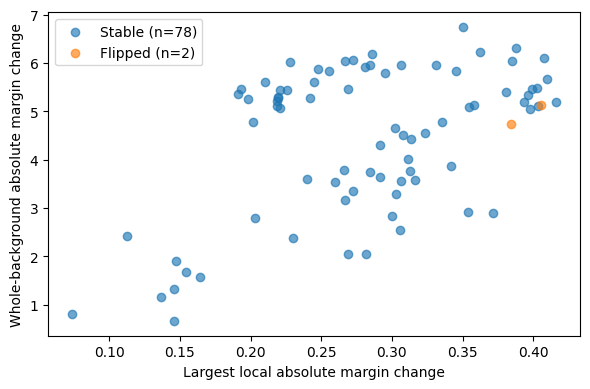

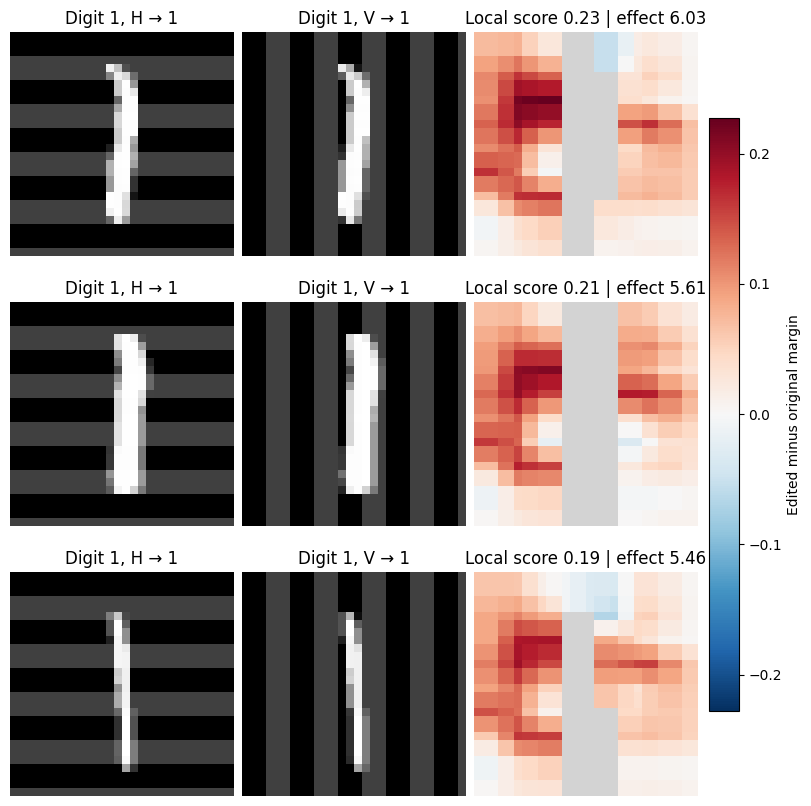

Results ZIP: /content/mnist_patch_results.zip


In [7]:
g = results[(results.seed == SEEDS[0]) & (results.agreement == .95)].copy()
g = g.set_index("test_id").reindex(test_ids).reset_index()
key = "gray_5"
fig, ax = plt.subplots(figsize=(6, 4))
for flipped, label in [(False, "Stable"), (True, "Flipped")]:
    t = g[g.flip == flipped]
    ax.scatter(t[key], t.effect, alpha=.65, label=f"{label} (n={len(t)})")
ax.set(xlabel="Largest local absolute margin change", ylabel="Whole-background absolute margin change")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "local_vs_global.png", dpi=160)
plt.show()

example_score = make_margin(keras.models.load_model(OUT / "example_model.keras"))
ids = (g.effect.rank(pct=True) - g[key].rank(pct=True)).dropna().nlargest(3).index.tolist()
assert ids, "No eligible 5x5 patches in the example cohort."
_, maps = local_scores(example_score, g.margin_h.to_numpy(), 5, "gray", ids, want_maps=True)
fig, axes = plt.subplots(len(ids), 3, squeeze=False, figsize=(8, 2.7*len(ids)),
                         constrained_layout=True)
limit = max(1e-6, max(np.nanmax(np.abs(maps[i])) for i in ids))
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("lightgray")
for row, i in enumerate(ids):
    rec = g.iloc[i]
    for ax, img, label in zip(axes[row,:2], (horizontal[i], vertical[i]), ("h", "v")):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Digit {digit[i]}, {label.upper()} → {int(rec['pred_'+label])}")
    im = axes[row,2].imshow(maps[i], cmap=cmap, vmin=-limit, vmax=limit)
    axes[row,2].set_title(f"Local score {rec[key]:.2f} | effect {rec.effect:.2f}")
    for ax in axes[row]:
        ax.axis("off")
fig.colorbar(im, ax=list(axes[:,2]), shrink=.75, label="Edited minus original margin")
fig.savefig(OUT / "discrepancy_examples.png", dpi=160)
plt.show()
archive = shutil.make_archive("mnist_patch_results", "zip", OUT)
print("Results ZIP:", archive)

## Signed-margin analysis

For the 95% and 100% agreement models, split the results by true digit and seed. Plot the initial margin against the signed change after the background swap. The line Δ = −m_H marks the decision threshold. This section uses the saved predictions and does not retrain the models.

TABLE 1: Breakdown by TRUE digit and training seed


,agreement,seed,digit,n,flips,flip_pct,flips_1_to_2,flips_2_to_1,initial_accuracy,median_mH,mean_mH,median_delta,mean_delta,median_abs_delta
0,0.95,11,1,40,2,5.0,2,0,1.000,-8.873,-8.472,5.466,5.575,5.466
1,0.95,11,2,40,0,0.0,0,0,1.000,9.539,10.147,3.544,3.337,3.544
2,0.95,23,1,40,3,7.5,3,0,1.000,-9.024,-8.665,5.046,5.050,5.046
3,0.95,23,2,40,0,0.0,0,0,1.000,9.136,9.139,3.832,3.922,3.832
4,1.00,11,1,40,40,100.0,40,0,1.000,-10.561,-10.447,13.860,13.900,13.860
5,1.00,11,2,40,16,40.0,16,0,0.600,1.245,1.462,9.571,9.528,9.571
6,1.00,23,1,40,40,100.0,40,0,1.000,-10.295,-10.204,13.883,13.941,13.883
7,1.00,23,2,40,19,47.5,19,0,0.525,0.130,0.180,10.640,10.929,10.640



TABLE 2: Flipped vs stable, within each group


,agreement,seed,digit,flip,images,median_mH,median_delta,median_abs_delta
0,0.95,11,1,False,38,-8.897,5.478,5.478
1,0.95,11,1,True,2,-3.908,4.935,4.935
2,0.95,11,2,False,40,9.539,3.544,3.544
3,0.95,23,1,False,37,-9.121,5.035,5.035
4,0.95,23,1,True,3,-4.425,5.394,5.394
5,0.95,23,2,False,40,9.136,3.832,3.832
6,1.00,11,1,True,40,-10.561,13.860,13.860
7,1.00,11,2,False,24,2.608,7.903,7.903
8,1.00,11,2,True,16,-2.431,11.995,11.995
9,1.00,23,1,True,40,-10.295,13.883,13.883


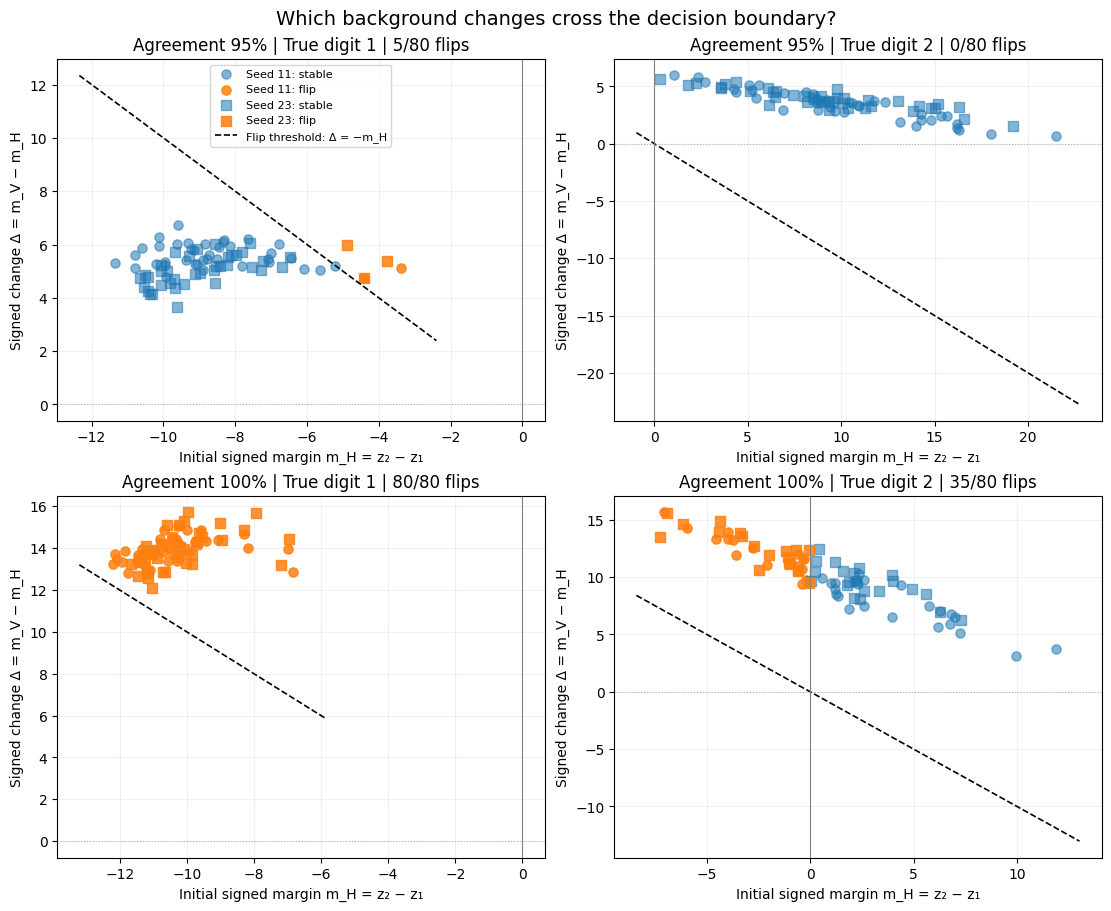

Saved 3 CSVs and the figure in: mnist_patch_results
Updated ZIP: /content/mnist_patch_results.zip


In [8]:
# Signed-margin analysis
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil
import zipfile

out_dir = Path('mnist_patch_results')
csv_path = out_dir / 'per_image.csv'

# Use existing results or load the saved CSV.
if 'results' in globals() and isinstance(results, pd.DataFrame):
    df = results.copy()
else:
    if not csv_path.exists() and Path('mnist_patch_results.zip').exists():
        out_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile('mnist_patch_results.zip') as z:
            z.extractall(out_dir)
    if not csv_path.exists():
        raise FileNotFoundError(
            'No per-image predictions found. Run the original experiment once, '
            'or upload its mnist_patch_results.zip (or per_image.csv into '
            'mnist_patch_results/) before running this cell.'
        )
    df = pd.read_csv(csv_path)

required = {'agreement', 'seed', 'test_id', 'digit', 'margin_h', 'margin_v'}
missing = required - set(df.columns)
if missing:
    raise ValueError(f'Missing per_image.csv columns: {sorted(missing)}')

# Filter to 95% and 100% agreement.
df = df.loc[np.isclose(df['agreement'], .95) | np.isclose(df['agreement'], 1.0)].copy()
if df.empty:
    raise ValueError('No rows found for 95% or 100% agreement.')

df['agreement'] = df['agreement'].round(2)
df['delta'] = df['margin_v'] - df['margin_h']   # signed change
df['abs_delta'] = df['delta'].abs()
df['pred_h'] = np.where(df['margin_h'] > 0, 2, 1)
df['pred_v'] = np.where(df['margin_v'] > 0, 2, 1)
df['flip'] = df['pred_h'] != df['pred_v']
df['correct_h'] = df['pred_h'] == df['digit']
df['flip_1_to_2'] = df['flip'] & (df['pred_h'] == 1)
df['flip_2_to_1'] = df['flip'] & (df['pred_h'] == 2)
df['direction'] = np.select(
    [df['flip_1_to_2'], df['flip_2_to_1']], ['1->2', '2->1'], default='stable'
)
# Assign ties to digit 1.

# Group by agreement, seed and digit.
summary = (df.groupby(['agreement', 'seed', 'digit'], as_index=False)
    .agg(n=('flip', 'size'), flips=('flip', 'sum'),
         flips_1_to_2=('flip_1_to_2', 'sum'), flips_2_to_1=('flip_2_to_1', 'sum'),
         initial_accuracy=('correct_h', 'mean'),
         median_mH=('margin_h', 'median'), mean_mH=('margin_h', 'mean'),
         median_delta=('delta', 'median'), mean_delta=('delta', 'mean'),
         median_abs_delta=('abs_delta', 'median')))
summary['flip_pct'] = 100 * summary['flips'] / summary['n']
summary = summary[['agreement', 'seed', 'digit', 'n', 'flips', 'flip_pct',
                   'flips_1_to_2', 'flips_2_to_1', 'initial_accuracy',
                   'median_mH', 'mean_mH', 'median_delta', 'mean_delta',
                   'median_abs_delta']]

# Split each group by flip outcome.
by_outcome = (df.groupby(['agreement', 'seed', 'digit', 'flip'], as_index=False)
    .agg(images=('test_id', 'size'),
         median_mH=('margin_h', 'median'),
         median_delta=('delta', 'median'),
         median_abs_delta=('abs_delta', 'median')))

out_dir.mkdir(parents=True, exist_ok=True)
summary.to_csv(out_dir / 'signed_margin_by_digit_seed.csv', index=False)
by_outcome.to_csv(out_dir / 'signed_margin_flip_vs_stable.csv', index=False)
detail = df[['agreement', 'seed', 'digit', 'test_id', 'pred_h', 'pred_v',
             'margin_h', 'margin_v', 'delta', 'abs_delta', 'flip',
             'direction', 'correct_h']].sort_values(['agreement', 'seed', 'digit', 'test_id'])
detail.to_csv(out_dir / 'signed_margin_per_image.csv', index=False)

print('TABLE 1: Breakdown by TRUE digit and training seed')
display(summary.round(3))
print('\nTABLE 2: Flipped vs stable, within each group')
display(by_outcome.round(3))

# Plot the margin and its change. The threshold is Delta = -m_H.
# Away from ties, a flip requires opposite signs.
fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
seed_values = sorted(df['seed'].unique())
markers = ['o', 's', '^', 'D', 'P', 'X', 'v']
for row, agreement in enumerate([.95, 1.0]):
    for col, digit_value in enumerate([1, 2]):
        ax = axes[row, col]
        group = df[(df['agreement'] == agreement) & (df['digit'] == digit_value)]
        for j, seed_value in enumerate(seed_values):
            for flipped in [False, True]:
                sub = group[(group['seed'] == seed_value) & (group['flip'] == flipped)]
                if sub.empty:
                    continue
                ax.scatter(sub['margin_h'], sub['delta'],
                           marker=markers[j % len(markers)], s=44,
                           color='tab:orange' if flipped else 'tab:blue',
                           alpha=.85 if flipped else .55,
                           label=f'Seed {seed_value}: {"flip" if flipped else "stable"}')
        if not group.empty:
            xmin, xmax = group['margin_h'].min(), group['margin_h'].max()
            padding = max(1., .06 * (xmax - xmin))
            xs = np.linspace(xmin - padding, xmax + padding, 200)
            ax.plot(xs, -xs, 'k--', linewidth=1.2, label='Flip threshold: Δ = −m_H')
        ax.axvline(0, color='0.5', linewidth=.8)
        ax.axhline(0, color='0.7', linewidth=.8, linestyle=':')
        ax.set(title=f'Agreement {agreement:.0%} | True digit {digit_value} | '
                     f'{int(group.flip.sum())}/{len(group)} flips',
               xlabel='Initial signed margin m_H = z₂ − z₁',
               ylabel='Signed change Δ = m_V − m_H')
        ax.grid(alpha=.18)
        if row == 0 and col == 0:
            ax.legend(fontsize=8)
fig.suptitle('Which background changes cross the decision boundary?', fontsize=14)
fig.savefig(out_dir / 'signed_margin_flip_boundary.png', dpi=170, bbox_inches='tight')
plt.show()

archive = shutil.make_archive('mnist_patch_results', 'zip', out_dir)
print('Saved 3 CSVs and the figure in:', out_dir)
print('Updated ZIP:', archive)
